# Practice exercise: Cwtch Rescue intake photos (student version)

**Computational AI · Dr Mabrouka Abuhmida · University of South Wales**

Cwtch Rescue is an animal rescue in the Valleys. When a cat or dog arrives, a volunteer takes its photo. The rescue wants to use these photos with a simple model that says "cat" or "dog". The photos are messy, so they need your help first.

You are their data engineer. You will check the data, clean it, prepare it for the model, and test it fairly. At the end you will finish a small app that prepares a new photo.

This is the same workflow as Assignment 2, on easier data.

## What you will do

| Task | What you do | Time |
| --- | --- | --- |
| 1 | Fix the labels | 20 min |
| 2 | Check the images | 20 min |
| 3 | Clean the images | 20 min |
| 4 | Split by animal and save | 20 min |
| 5 | Test with the model | 15 min |
| 6 | Finish the app | 30 min |
| 7 | Write a decision log | 15 min |

Most of the code is given. You fill in short pieces marked `TODO`. Work in pairs. Write short answers where you see **Your answer**.

**Submission:** when you finish, click Kernel > Restart and Run All, then upload this notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## Before you start

1. Download `cwtch_pet_intake.zip` from the module page.
2. Put it in the **same folder as this notebook**. Do not unzip it: the first code cell does that.
   - Colab: click the folder icon on the left and upload the zip.
   - VS Code: copy the zip next to the notebook.
3. The zip has a folder of 284 photos, a table called `intake_metadata.csv`, and `app_starter.py` for Task 6.

You need `numpy`, `pandas`, `matplotlib`, `Pillow`, `scikit-image` and `scikit-learn`. For Task 6 you also need `streamlit`.

The photos come from the Oxford-IIIT Pet dataset (Parkhi et al., 2012), shared under CC BY-SA 4.0. We added the problems on purpose.

## Setup

Run this cell. It unzips the data and loads the table.

In [13]:
import json
import hashlib
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage import util, filters, transform
from sklearn.model_selection import GroupShuffleSplit, train_test_split

pd.set_option("display.width", 160)
DATA = Path("cwtch_pet_intake")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

# Unzip the data the first time you run this cell
if not DATA.exists():
    zipfile.ZipFile("cwtch_pet_intake.zip").extractall(".")

meta = pd.read_csv(DATA / "intake_metadata.csv", keep_default_na=False)
print("Rows in the metadata:", len(meta))
meta.head()

Rows in the metadata: 284


,file_name,animal_id,intake_date,device,species_entered,breed_entered
0,IMG_0001.jpg,A001,2026-09-11,night_cam,dog,Shiba Inu
1,IMG_0002.jpg,A001,2026-09-11,night_cam,dog,Shiba Inu
2,IMG_0003.jpg,A001,2026-09-11,night_cam,Dog,Shiba Inu
3,IMG_0004.jpg,A002,2026-10-16,volunteer_phone,Puppy,Chihuahua
4,IMG_0005.jpg,A002,2026-10-16,volunteer_phone,Puppy,Chihuahua


## Look at four photos

One photo from each kind of source. Look closely at the second and third photos. What is wrong with them?

Run this cell.

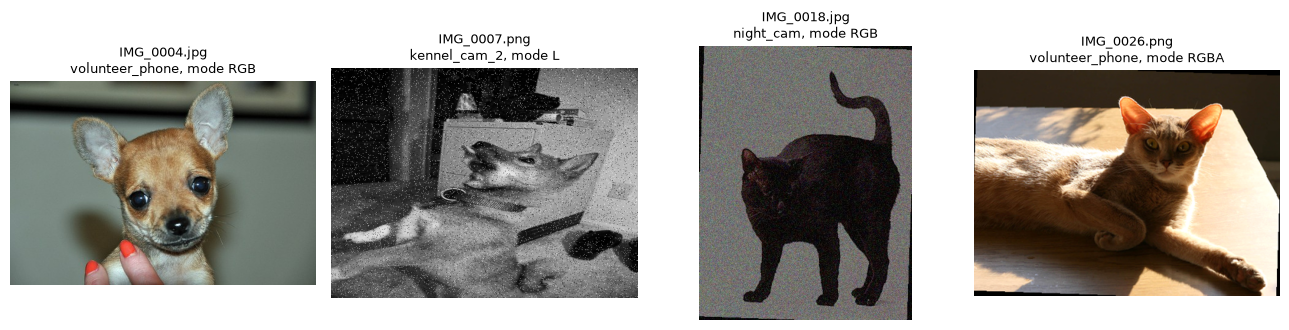

In [14]:
examples = ["IMG_0004.jpg", "IMG_0007.png", "IMG_0018.jpg", "IMG_0026.png"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, name in zip(axes, examples):
    img = Image.open(DATA / "images" / name)
    device = meta.loc[meta["file_name"] == name, "device"].iloc[0]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{name}\n{device}, mode {img.mode}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Three helper functions

Run this cell. It gives you three functions you will use all session.

- `load_grey(path)` opens a photo in greyscale, with values from 0 (black) to 1 (white).
- `sp_level(grey)` measures **dots**: tiny black and white specks (called salt and pepper noise). Bigger means more dots.
- `noise_level(grey)` measures **grain**: a fuzzy, sandy look (called Gaussian noise). Bigger means more grain.

These are estimates, so always check them against the pictures.

In [ ]:


DATA = Path("cwtch_pet_intake")

def load_grey(path):
    """Open an image as greyscale, with values from 0 to 1."""
    return util.img_as_float(np.asarray(Image.open(path).convert("L")))


def sp_level(grey):
    """Share of pixels that are very different from their neighbours (salt and pepper dots)."""
    smooth = filters.median(grey, np.ones((3, 3)))
    return float((np.abs(grey - smooth) > 0.4).mean())


def noise_level(grey):
    """How grainy the image is. Bigger means more grain."""
    h, w = grey.shape
    g = grey[: h // 2 * 2, : w // 2 * 2]
    diagonal = (g[0::2, 0::2] - g[0::2, 1::2] - g[1::2, 0::2] + g[1::2, 1::2]) / 2
    return float(np.median(np.abs(diagonal)) / 0.6745)


for name in ["IMG_0004.jpg", "IMG_0007.png", "IMG_0018.jpg"]:
    grey = load_grey(DATA / "images" / name)
    print(name, " dots:", round(sp_level(grey), 3), " grain:", round(noise_level(grey), 3))

IMG_0004.jpg  dots: 0.0  grain: 0.003
IMG_0007.png  dots: 0.038  grain: 0.009
IMG_0018.jpg  dots: 0.0  grain: 0.052


# Part 1: understand the data

## Reminder: labels are data too

Volunteers typed the labels by hand. Some wrote "Cat", some "kitten", some left it blank. We fix this the same way as in Week 3.

- `.value_counts()` counts each value. Always start with it.
- `.str.strip()` removes extra spaces. `.str.lower()` makes all letters small.
- `.replace({"old": "new"})` swaps one value for another.
- One animal can have up to three photos. All its photos must have the same label.

### Student Task 1: fix the labels

**Goal:** give every photo one clean label: `cat` or `dog`.

**Steps:**
1. Run `value_counts()` on `species_entered`. How many spellings are there?
2. Make a new column `label`: remove spaces, make it lower case, change `kitten` to `cat` and `puppy` to `dog`, and change blanks to `np.nan`.
3. Run the given code that lists animals whose photos disagree.
4. Look at `breed_entered` for those animals and fill in `fixes` with `cat` or `dog`. Then run the rest of the cell.

**Expected output:** 15 spellings become `cat` and `dog`. Three animals (A025, A095 and A128) have both labels. After the fix, 160 photos are cats, 118 are dogs and 6 have no label.

**Reflection question:** why is the breed better evidence than counting the photos?

In [17]:
# Step 1
print(meta["species_entered"].value_counts())

# TODO Step 2: make the new column
# Hint: meta["species_entered"].str.strip().str.lower().replace({"kitten": "cat", "puppy": "dog", "": np.nan})
meta["label"] = (
meta["species_entered"]
    .str.strip()
    .str.lower()
    .replace({"kitten": "cat", "puppy": "dog", "": np.nan})
)
print(meta["label"].value_counts(dropna=False))

# Step 3 (given): animals whose photos disagree
per_animal = meta.groupby("animal_id")["label"].nunique()
conflicts = per_animal[per_animal > 1].index
print(meta.loc[meta["animal_id"].isin(conflicts), ["file_name", "animal_id", "label", "breed_entered"]])

# TODO Step 4: read the breed above and write "cat" or "dog"
fixes = {"A025": "cat", "A095": "dog", "A128": "cat"}

# Given: apply the fixes, then give every photo its animal's label
for animal, species in fixes.items():
    meta.loc[meta["animal_id"] == animal, "label"] = species
animal_label = meta.dropna(subset=["label"]).groupby("animal_id")["label"].first()
meta["label_clean"] = meta["animal_id"].map(animal_label)
print(meta["label_clean"].value_counts(dropna=False))

species_entered
cat       85
dog       54
Dog       31
Cat       31
          19
kitten     9
CAT        8
cat        8
Puppy      7
DOG        6
 Dog       6
puppy      6
 cat       5
Kitten     5
dog        4
Name: count, dtype: int64
label
cat    151
dog    114
NaN     19
Name: count, dtype: int64
        file_name animal_id label      breed_entered
46   IMG_0047.jpg      A025   dog             Birman
47   IMG_0048.jpg      A025   cat             Birman
48   IMG_0049.jpg      A025   NaN             Birman
179  IMG_0180.jpg      A095   cat              boxer
180  IMG_0181.jpg      A095   dog              boxer
181  IMG_0182.jpg      A095   NaN              boxer
253  IMG_0254.jpg      A128   dog  British Shorthair
254  IMG_0255.jpg      A128   cat  British Shorthair
255  IMG_0256.jpg      A128   NaN  British Shorthair
label_clean
cat    160
dog    118
NaN      6
Name: count, dtype: int64


**Your answer:**

_Write here._

## Reminder: check every image

In Week 6 we looked at one image as numbers. Now we have 284, so we put the numbers in a table, one row per photo.

The next cell is given. It opens every photo and records whether it opens, its size, its colour mode, its brightness, its contrast, its dots and its grain. It also records an `md5`: a fingerprint of the file. Two files with the same fingerprint are the same file.

Run it. It takes about 30 seconds.

In [18]:
def audit_image(path):
    row = {"file_name": path.name}
    try:
        img = Image.open(path)
        img.load()                      # read every pixel; broken files fail here
    except Exception as err:
        row["readable"] = False
        return row
    grey = util.img_as_float(np.asarray(img.convert("L")))
    row.update(readable=True, width=img.width, height=img.height, mode=img.mode,
               brightness=grey.mean(), contrast=grey.std(),
               sp=sp_level(grey), noise=noise_level(grey),
               md5=hashlib.md5(path.read_bytes()).hexdigest())
    return row

audit = pd.DataFrame([audit_image(DATA / "images" / f) for f in meta["file_name"]])
df = meta.merge(audit, on="file_name")
df.head()

,file_name,animal_id,intake_date,device,species_entered,breed_entered,label,label_clean,readable,width,height,mode,brightness,contrast,sp,noise,md5
0,IMG_0001.jpg,A001,2026-09-11,night_cam,dog,Shiba Inu,dog,dog,True,500.0,335.0,RGB,0.101954,0.075575,0.000000,0.049419,3eb1fcf5f46e2a871070724627153173
1,IMG_0002.jpg,A001,2026-09-11,night_cam,dog,Shiba Inu,dog,dog,True,500.0,335.0,RGB,0.106164,0.078435,0.000000,0.049419,3b09e25438342315bb493c289eb6a452
2,IMG_0003.jpg,A001,2026-09-11,night_cam,Dog,Shiba Inu,dog,dog,True,500.0,335.0,RGB,0.103975,0.077307,0.000000,0.049419,3271cd659ff4e303b64c630b4e31989a
3,IMG_0004.jpg,A002,2026-10-16,volunteer_phone,Puppy,Chihuahua,dog,dog,True,500.0,332.0,RGB,0.442657,0.151597,0.000030,0.002907,9d7ac607fb40ba4eae836a5b63146873
4,IMG_0005.jpg,A002,2026-10-16,volunteer_phone,Puppy,Chihuahua,dog,dog,True,500.0,332.0,RGB,0.399976,0.147088,0.000024,0.002907,2cb5a11c885526af29b6e2cbf8f070b0


### Student Task 2: check the images

**Goal:** use the table `df` to find what is wrong.

**Steps:**
1. Count the photos that cannot be opened.
2. Count the colour modes, and find the smallest and largest width.
3. Show the median `brightness`, `sp` and `noise` for each `device`.
4. List the blank photos: those with `contrast` under 0.02.

**Expected output:** 4 photos cannot be opened. 215 are RGB, 35 are L (greyscale) and 30 are RGBA. Widths go from 190 to 1,281. The kennel camera has the most dots. The night camera is the darkest and has the most grain. 3 photos are blank.

**Reflection question:** which camera would you ask the rescue to repair first, and why?

In [19]:
# TODO: Complete this task
# Hint Step 1: (~df["readable"]).sum()
print("Cannot open:", (~df["readable"]).sum())

# Hint Step 2: df["mode"].value_counts() and df["width"].min(), df["width"].max()
print("Mode distribution:")
print(df["mode"].value_counts())
print("Width range:")
print("Min:", df["width"].min())
print("Max:", df["width"].max())

# Hint Step 3: df.groupby("device")[["brightness", "sp", "noise"]].median()
print(df.groupby("device")[["brightness", "sp", "noise"]].median().round(3))

# Hint Step 4: df.loc[df["contrast"] < 0.02, ["file_name", "device", "contrast"]]
print(df.loc[df["contrast"] < 0.02, ["file_name", "device", "contrast"]])



Cannot open: 4
Mode distribution:
mode
RGB     215
L        35
RGBA     30
Name: count, dtype: int64
Width range:
Min: 190.0
Max: 1281.0
                 brightness     sp  noise
device                                   
kennel_cam_2          0.431  0.035  0.006
night_cam             0.202  0.000  0.055
volunteer_phone       0.452  0.000  0.006
        file_name     device  contrast
281  IMG_0282.jpg  night_cam  0.001871
282  IMG_0283.jpg  night_cam  0.001857
283  IMG_0284.jpg  night_cam  0.001895


**Your answer:**

_Write here._

## Chart: what each camera does

Three box plots, one for each measure. Find the camera that stands apart in each one. Run this cell.

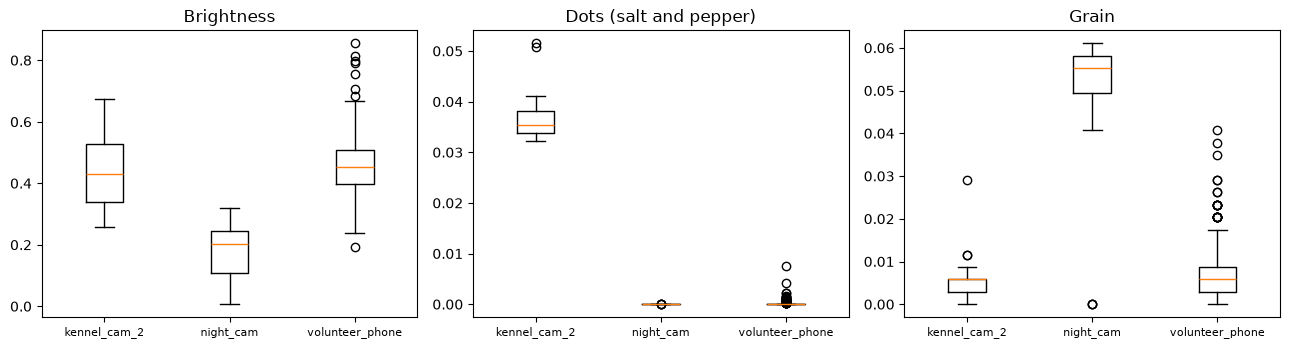

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
devices = sorted(df["device"].unique())
for ax, col, title in zip(axes, ["brightness", "sp", "noise"], ["Brightness", "Dots (salt and pepper)", "Grain"]):
    ax.boxplot([df.loc[df["device"] == d, col].dropna() for d in devices])
    ax.set_xticks([1, 2, 3], devices, fontsize=8)
    ax.set_title(title)
plt.tight_layout()
plt.show()

### Your quality note

Write three sentences for the rescue manager. Say what is wrong, how many photos it affects, and which camera causes it.

**Your answer:**

_Write here._

# Part 2: prepare the data

## Reminder: match the filter to the problem

From Week 6:

- **Dots** (salt and pepper): use a **median filter**. `filters.median(grey, np.ones((3, 3)))` replaces each pixel with the middle value of its 3 by 3 neighbours. It removes dots and keeps edges sharp.
- **Grain** (Gaussian noise): use a **Gaussian filter**. `filters.gaussian(grey, sigma=1)` softly averages each pixel with its neighbours. It also blurs a little, so only use it when there is grain.

We choose the filter from the measured numbers, not from the camera name. A new photo in the app will not come with a camera name.

### Student Task 3: clean the images

**Goal:** remove the photos we cannot use, and clean the rest.

**Steps:**
1. Finish `clean_image`: the median filter is done for you. Add the Gaussian filter for grain, the same way.
2. Keep only photos that open, are not blank, are not duplicates and have a label. Call the result `clean`.
3. Run the rest of the cell to see before and after, and to count how often each filter is used.

**Expected output:** 271 photos of 135 animals are kept. The median filter is used on 35 photos and the Gaussian filter on 39.

**Reflection question:** one duplicate pair belongs to two different animals (IMG_0051 and IMG_0176). What could have gone wrong at the rescue?

In [ ]:
SETTINGS = {"sp_threshold": 0.01, "noise_threshold": 0.03, "size": 64}

def clean_image(grey, s):
    steps = []
    if sp_level(grey) > s["sp_threshold"]:
        grey = filters.median(grey, np.ones((3, 3)))
        steps.append("median filter 3x3 (dots)")
    # TODO Step 1: add an elif for grain
    # Hint: elif noise_level(grey) > s["noise_threshold"]:
    # Hint:     grey = filters.gaussian(grey, sigma=1)
    # Hint:     steps.append("Gaussian filter, sigma 1 (grain)")
    return grey, steps

# TODO Step 2: remove what we cannot use
# Hint: df["blank"] = df["contrast"] < 0.02
# Hint: df["duplicate"] = df["readable"] & df.duplicated("md5")
# Hint: keep = df["readable"] & ~df["blank"] & ~df["duplicate"] & df["label_clean"].notna()
# Hint: clean = df[keep].reset_index(drop=True)
# Add your code here

# Step 3 (given): before and after
fig, axes = plt.subplots(2, 2, figsize=(8, 6.5))
for r, name in enumerate(["IMG_0007.png", "IMG_0018.jpg"]):
    grey = load_grey(DATA / "images" / name)
    after, steps = clean_image(grey, SETTINGS)
    axes[r, 0].imshow(grey, cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title(f"{name} before", fontsize=9)
    axes[r, 1].imshow(after, cmap="gray", vmin=0, vmax=1)
    axes[r, 1].set_title(steps[0] if steps else "no change", fontsize=9)
    for a in axes[r]:
        a.axis("off")
plt.tight_layout()
plt.show()

# Step 3 (given): how many images does each filter change?
all_steps = [clean_image(load_grey(DATA / "images" / f), SETTINGS)[1] for f in clean["file_name"]]
print(pd.Series([s[0] if s else "no filter" for s in all_steps]).value_counts())

**Your answer:**

_Write here._

## Reminder: split by animal

Most animals have two or three photos taken seconds apart. They look almost the same. If one photo goes into training and its twin goes into testing, the model is tested on a picture it has nearly seen. This is called a **leak**, and it makes the model look better than it is.

The fix: put **all photos of one animal on the same side**. `GroupShuffleSplit` does this for you.

The next cell is given. It defines two functions and builds `X`, `y` and `groups`:

- `prepare_image` changes a photo to greyscale, cleans it, cuts a square from the centre and shrinks it to 64 by 64.
- `save_run` learns the mean and standard deviation from the **training** photos only, uses them to scale both sides, and saves four files. This is the Week 5 rule: learn on train, apply to test.

Run it.

In [ ]:
def prepare_image(img, s):
    grey = util.img_as_float(np.asarray(img.convert("L")))
    steps = [f"converted {img.mode} {img.width}x{img.height} to greyscale"]
    grey, cleaning_steps = clean_image(grey, s)
    steps += cleaning_steps
    h, w = grey.shape
    m = min(h, w)
    top, left = (h - m) // 2, (w - m) // 2
    grey = grey[top:top + m, left:left + m]                     # square from the centre
    small = transform.resize(grey, (s["size"], s["size"]), anti_aliasing=True)
    steps.append(f"cropped to {m}x{m} and resized to {s['size']}x{s['size']}")
    return small, steps


def save_run(name, train_rows, test_rows):
    folder = OUT / name
    folder.mkdir(exist_ok=True)
    mean, std = X[train_rows].mean(), X[train_rows].std()       # learned from train only
    np.save(folder / "X_train.npy", (X[train_rows] - mean) / std)
    np.save(folder / "y_train.npy", y[train_rows])
    np.save(folder / "X_test.npy", (X[test_rows] - mean) / std)
    np.save(folder / "y_test.npy", y[test_rows])
    print(f"Saved {name}: {len(train_rows)} train, {len(test_rows)} test")
    return float(mean), float(std)


X = np.array([prepare_image(Image.open(DATA / "images" / f), SETTINGS)[0] for f in clean["file_name"]])
y = (clean["label_clean"] == "dog").astype(int).to_numpy()     # 0 = cat, 1 = dog
groups = clean["animal_id"].to_numpy()
print("X:", X.shape, " dogs:", y.sum(), " cats:", (y == 0).sum())

### Student Task 4: split by animal and save

**Goal:** make a fair split with no leak, and save the files the model and the app need.

**Steps:**
1. Split by animal with `GroupShuffleSplit`, using `test_size=0.25` and `random_state=42`.
2. Print how many animals are on both sides. It must be 0.
3. Run the given random split and see how many animals it puts on both sides.
4. Save both splits with `save_run`. Keep `train_mean` and `train_std` from the grouped split. The last lines save them to `prep_settings.json` for the app.

**Expected output:** the grouped split has 0 animals on both sides. The random split has 46. The train mean is about 0.429 and the standard deviation about 0.246.

**Reflection question:** why must the app use the saved mean and standard deviation, and not work them out from the uploaded photo?

In [ ]:
# TODO Step 1: split by animal
# Hint: splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
# Hint: train_idx, test_idx = next(splitter.split(X, y, groups))

# TODO Step 2: how many animals are on both sides?
# Hint: len(set(groups[train_idx]) & set(groups[test_idx]))

# Step 3 (given): the random split, for comparison
leaky_train, leaky_test = train_test_split(np.arange(len(y)), test_size=0.25, random_state=42, stratify=y)
print("Random split, animals on both sides:", len(set(groups[leaky_train]) & set(groups[leaky_test])))

# TODO Step 4: save both runs
# Hint: train_mean, train_std = save_run("grouped", train_idx, test_idx)
# Hint: save_run("leaky", leaky_train, leaky_test)

# Given: save the settings for the app
settings_out = {**SETTINGS, "train_mean": train_mean, "train_std": train_std}
(OUT / "prep_settings.json").write_text(json.dumps(settings_out, indent=2))
print(settings_out)

**Your answer:**

_Write here._

# Part 3: test it

## The model (given)

You do not build a model in this module. We give you one. It looks at the edges in each photo and learns which edge patterns mean cat and which mean dog. It is simple on purpose. You use it to test your **data** decisions.

It reports:
- **accuracy**: the share of test photos it gets right;
- **balanced accuracy**: the average of "cats found" and "dogs found". It is fairer here because there are more cats than dogs;
- **cats found** and **dogs found**: the share of each it got right.

Run this cell. Do not change it.

In [ ]:
# Provided model: do not edit this cell
from skimage.feature import hog
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score

def run_classifier(folder):
    folder = Path(folder)
    X_tr, y_tr = np.load(folder / "X_train.npy"), np.load(folder / "y_train.npy")
    X_te, y_te = np.load(folder / "X_test.npy"), np.load(folder / "y_test.npy")
    features = lambda A: np.array([hog(a, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for a in A])
    model = LogisticRegression(C=0.1, max_iter=3000).fit(features(X_tr), y_tr)
    pred = model.predict(features(X_te))
    return {"run": folder.name,
            "accuracy": round(accuracy_score(y_te, pred), 2),
            "balanced accuracy": round(balanced_accuracy_score(y_te, pred), 2),
            "cats found": round(recall_score(y_te, pred, pos_label=0), 2),
            "dogs found": round(recall_score(y_te, pred, pos_label=1), 2)}

print("Model ready.")

### Student Task 5: test with the model

**Goal:** see what the leak does to the result.

**Steps:**
1. Run `run_classifier` on `outputs/grouped` and on `outputs/leaky`, and put both results in a table called `results`.
2. Compare the balanced accuracy of the two runs.
3. Compare cats found with dogs found.

**Expected output:** the random (leaky) split scores higher: balanced accuracy about 0.73 against about 0.63. The model finds more cats than dogs. Your numbers may differ a little.

**Reflection question:** the rescue will see only one number. Which one would you give them, and why?

In [ ]:
# TODO: Complete this task
# Hint: pd.DataFrame([run_classifier(OUT / "grouped"), run_classifier(OUT / "leaky")])
results = ...
results

## Chart: same photos, same model, different split

Run this cell after Task 5. The dashed line is what guessing would score.

In [ ]:
plt.figure(figsize=(6, 3.4))
plt.bar(results["run"], results["balanced accuracy"], color=["#CA0437", "#6E6E6E"])
plt.axhline(0.5, color="#333333", linestyle="--", label="guessing")
plt.ylim(0, 1)
plt.ylabel("balanced accuracy")
plt.title("Same photos, same model, different split")
plt.legend()
plt.tight_layout()
plt.show()

**Your answer:**

_Write here._

# Part 4: the app

## Reminder: the app must match the notebook

The app prepares one new photo the same way as the notebook. Two rules:

- It uses the **same functions** as the notebook. They are already copied into `app_starter.py`.
- It reads the **saved settings** from `outputs/prep_settings.json`. It never works them out again.

### Student Task 6: finish the app

**Goal:** finish `app_starter.py` so it prepares an uploaded photo and shows what it did.

**Steps:**
1. Run the check cell below. It must print `True`.
2. Open `app_starter.py` (it was in the zip). It already runs. Do TODO 1, 2 and 3.
3. In a terminal, in this folder, type `streamlit run app_starter.py`. (Colab users: download your `outputs` folder and run the app in VS Code.)
4. Test it with `IMG_0007.png`, `IMG_0018.jpg`, the broken `IMG_0100.jpg` and the blank `IMG_0282.jpg` (all in `cwtch_pet_intake/images`).

**Expected output:** `IMG_0007.png` lists four steps, including "median filter 3x3 (dots)". `IMG_0100.jpg` shows an error message and does not crash. `IMG_0282.jpg` is refused as blank.

**Reflection question:** a volunteer uploads a photo of a rabbit. What will the app do?

In [ ]:
# The app must prepare a photo exactly like the notebook does. Check one here.
saved = json.loads((OUT / "prep_settings.json").read_text())
name = "IMG_0007.png"
prepared, steps = prepare_image(Image.open(DATA / "images" / name), saved)
row = clean.index[clean["file_name"] == name][0]
print("Steps:", steps)
print("Same as the notebook:", np.allclose(prepared, X[row]))

**Your answer:**

_Write here._

# Pulling it together

### Student Task 7: write a decision log

**Goal:** record your three most important decisions, as you will in the Assignment 2 report.

**Steps:**
1. The first row is an example. Replace `LEAKY` and `GROUPED` with your numbers from Task 5.
2. Add two more rows: one about cleaning and one about removing files.
3. In `evidence`, use a number from your own results.

**Expected output:** a table with 3 rows and 3 columns.

**Reflection question:** which decision would you defend first if someone said your accuracy was too low?

In [ ]:
decision_log = pd.DataFrame([
    ["Split by animal, not at random",
     "Most animals have 2 or 3 photos; the random split put 46 animals on both sides",
     "Balanced accuracy dropped from LEAKY to GROUPED: the lower number is the honest one"],
    # TODO: add a row about cleaning
    # TODO: add a row about removing files
], columns=["decision", "evidence", "effect"])
pd.set_option("display.max_colwidth", 90)
decision_log

**Your answer:**

_Write here._

## Reflection

Which decision changed the result the most today? What does that tell you about where to spend your time in Assignment 2? Write about 80 words.

**Your answer:**

_Write here._

---

When you finish: Kernel > Restart and Run All, then upload the notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## References

- Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012) 'Leakage in data mining: formulation, detection, and avoidance', *ACM Transactions on Knowledge Discovery from Data*, 6(4), article 15.
- Parkhi, O.M., Vedaldi, A., Zisserman, A. and Jawahar, C.V. (2012) 'Cats and dogs', *IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, pp. 3498 to 3505. Dataset available at: https://www.robots.ox.ac.uk/~vgg/data/pets/ (CC BY-SA 4.0).
- scikit-image contributors (2024) *scikit-image documentation*. Available at: https://scikit-image.org/docs/stable/
- scikit-learn developers (2024) *GroupShuffleSplit*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html
- Streamlit (2024) *Streamlit documentation*. Available at: https://docs.streamlit.io/